# ANLP Assignment: Sentiment Classification

In this assignment, you will be investigating NLP methods for distinguishing positive and negative reviews written about movies.

For assessment, you are expected to complete and submit this notebook file.  When answers require code, you may import and use library functions (unless explicitly told otherwise).  All of your own code should be included in the notebook rather than imported from elsewhere.  Written answers should also be included in the notebook.  You should insert as many extra cells as you want and change the type between code and markdown as appropriate.

In order to avoid misconduct, you should not talk about the assignment questions with your peers.  If you are not sure what a question is asking you to do or have any other questions, please ask me or one of the Teaching Assistants.

Marking guidelines are provided as a separate document.

The first few cells contain code to set-up the assignment and bring in some data.   In order to provide unique datasets for analysis by different students, you must enter your candidate number in the following cell.  Otherwise do not change the code in these cells.

In [27]:
candidateno=326110 #this MUST be updated to your candidate number so that you get a unique data sample


In [28]:
#do not change the code in this cell
#preliminary imports

#set up nltk
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('movie_reviews')
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.corpus import movie_reviews

#for setting up training and testing data
import random

#useful other tools
import re
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from itertools import zip_longest
from nltk.probability import FreqDist
from nltk.classify.api import ClassifierI


[nltk_data] Downloading package punkt to /Users/bekzat/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/bekzat/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/bekzat/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package movie_reviews to
[nltk_data]     /Users/bekzat/nltk_data...
[nltk_data]   Package movie_reviews is already up-to-date!


In [29]:
#do not change the code in this cell
def split_data(data, ratio=0.7): # when the second argument is not given, it defaults to 0.7
    """
    Given corpus generator and ratio:
     - partitions the corpus into training data and test data, where the proportion in train is ratio,

    :param data: A corpus generator.
    :param ratio: The proportion of training documents (default 0.7)
    :return: a pair (tuple) of lists where the first element of the
            pair is a list of the training data and the second is a list of the test data.
    """

    data = list(data)
    n = len(data)
    train_indices = random.sample(range(n), int(n * ratio))
    test_indices = list(set(range(n)) - set(train_indices))
    train = [data[i] for i in train_indices]
    test = [data[i] for i in test_indices]
    return (train, test)


def get_train_test_data():

    #get ids of positive and negative movie reviews
    pos_review_ids=movie_reviews.fileids('pos')
    neg_review_ids=movie_reviews.fileids('neg')

    #split positive and negative data into training and testing sets
    pos_train_ids, pos_test_ids = split_data(pos_review_ids)
    neg_train_ids, neg_test_ids = split_data(neg_review_ids)
    #add labels to the data and concatenate
    training = [(movie_reviews.words(f),'pos') for f in pos_train_ids]+[(movie_reviews.words(f),'neg') for f in neg_train_ids]
    testing = [(movie_reviews.words(f),'pos') for f in pos_test_ids]+[(movie_reviews.words(f),'neg') for f in neg_test_ids]

    return training, testing

When you have run the cell below, your unique training and testing samples will be stored in `training_data` and `testing_data`

In [30]:
#do not change the code in this cell
random.seed(candidateno)
training_data,testing_data=get_train_test_data()
print("The amount of training data is {}".format(len(training_data)))
print("The amount of testing data is {}".format(len(testing_data)))
print("The representation of a single data item is below")
print(training_data[0])

The amount of training data is 1400
The amount of testing data is 600
The representation of a single data item is below
(['true', 'faith', 'and', 'its', 'expression', ...], 'pos')


1)  
a) **Generate** a list of 10 content words which are representative of the positive reviews in your training data.

b) **Generate** a list of 10 content words which are representative of the negative reviews in your training data.

c) **Explain** what you have done and why

[20\%]

In [31]:
from collections import Counter

stop_words = set(stopwords.words("english"))

def clean_words(review):
    return {
        word.lower()
        for word in review
        if word.isalpha()
        and len(word) >= 3
        and word.lower() not in stop_words
    }

In [32]:
def rank_words(data, min_documents=10):

    pos_counts = Counter()
    neg_counts = Counter()

    n_pos = 0
    n_neg = 0

    for review, label in data:
        words = clean_words(review)

        if label == "pos":
            pos_counts.update(words)
            n_pos += 1
        else:
            neg_counts.update(words)
            n_neg += 1

    all_words = set(pos_counts) | set(neg_counts)

    scores = {}

    for word in all_words:
        total = pos_counts[word] + neg_counts[word]

        if total >= min_documents:
            pos_rate = pos_counts[word] / n_pos
            neg_rate = neg_counts[word] / n_neg

            scores[word] = pos_rate - neg_rate

    positive_ranking = sorted(
        [w for w in scores if scores[w] > 0],
        key=lambda w: (-scores[w], w)
    )

    negative_ranking = sorted(
        [w for w in scores if scores[w] < 0],
        key=lambda w: (scores[w], w)
    )

    return (
        positive_ranking,
        negative_ranking,
        scores,
        pos_counts,
        neg_counts
    )

In [33]:
positive_ranking, negative_ranking, scores, pos_counts, neg_counts = rank_words(
    training_data
)

positive_words = positive_ranking[:10]
negative_words = negative_ranking[:10]

print("Positive words:")
print(positive_words)

print("\nNegative words:")
print(negative_words)

Positive words:
['life', 'also', 'great', 'well', 'perfect', 'american', 'performance', 'young', 'best', 'performances']

Negative words:
['bad', 'worst', 'script', 'plot', 'least', 'boring', 'nothing', 'stupid', 'supposed', 'ridiculous']


In [34]:
word_table = pd.DataFrame({
    "Positive word": positive_words,
    "Positive score": [scores[w] for w in positive_words],
    "Negative word": negative_words,
    "Negative score": [scores[w] for w in negative_words]
})

display(word_table.round(3))

,Positive word,Positive score,Negative word,Negative score
0,life,0.149,bad,-0.251
1,also,0.146,worst,-0.154
2,great,0.121,script,-0.133
3,well,0.107,plot,-0.131
4,perfect,0.101,least,-0.126
5,american,0.100,boring,-0.123
6,performance,0.099,nothing,-0.123
7,young,0.099,stupid,-0.120
8,best,0.097,supposed,-0.110
9,performances,0.097,ridiculous,-0.104


### 1 — Explanation

I ranked words using their relative document frequencies in the training set. After lowercasing, I removed punctuation, short tokens and English stopwords. I counted a word once per review rather than counting all its occurrences.

For each word, I subtracted its relative frequency in negative reviews from its relative frequency in positive reviews. A positive difference indicates a stronger association with positive reviews, while a negative difference indicates a stronger association with negative reviews. I excluded words appearing in fewer than 10 training documents to reduce the influence of rare terms.

I selected the ten highest positive scores and ten most negative scores. This is a data-driven measure of **association**, not necessarily of positive or negative meaning: for example, *also* is highly ranked but does not directly express sentiment. This is a limitation of frequency-based word selection. The test reviews were not used to create the lists.

2)
a) **Use** the lists generated in Q1 to build a **word list classifier** which will classify reviews as being positive or negative.

b) **Explain** what you have done.

[12.5\%]


In [35]:
def predict_wordlist(review, pos_list, neg_list):

    words = clean_words(review)

    pos_hits = len(words & set(pos_list))
    neg_hits = len(words & set(neg_list))

    if pos_hits >= neg_hits:
        return "pos"

    return "neg"

In [36]:
test_labels = [
    label for review, label in testing_data
]

wordlist_predictions = [
    predict_wordlist(review, positive_words, negative_words)
    for review, label in testing_data
]

print("First 10 predictions:")

for i in range(10):
    print(
        "Actual:", test_labels[i],
        "| Predicted:", wordlist_predictions[i]
    )

First 10 predictions:
Actual: pos | Predicted: pos
Actual: pos | Predicted: pos
Actual: pos | Predicted: pos
Actual: pos | Predicted: neg
Actual: pos | Predicted: pos
Actual: pos | Predicted: pos
Actual: pos | Predicted: pos
Actual: pos | Predicted: pos
Actual: pos | Predicted: pos
Actual: pos | Predicted: pos


### 2 — Explanation

I created a rule-based classifier using the two ten-word lists from Question 1. For each review, I remove stopwords and count the number of **distinct** words that match each list. The class with more matches is predicted; ties are assigned to the positive class.

The method is simple and interpretable because predictions can be traced to specific word matches. However, the tie-breaking rule favours positive predictions, and the classifier ignores word order, negation and all words outside the selected lists.

3)
a) **Calculate** the accuracy, precision, recall and F1 score of your classifier.

b) Is it reasonable to evaluate the classifier in terms of its accuracy?  **Explain** your answer and give a counter-example (a scenario where it would / would not be reasonable to evaluate the classifier in terms of its accuracy).

[20\%]

In [37]:
def evaluate(y_true, y_pred):

    confusion = Counter(zip(y_true, y_pred))

    correct = (
        confusion[("pos", "pos")]
        + confusion[("neg", "neg")]
    )

    results = {
        "Accuracy": correct / len(y_true)
    }

    for label in ("pos", "neg"):

        other = "neg" if label == "pos" else "pos"

        tp = confusion[(label, label)]
        fp = confusion[(other, label)]
        fn = confusion[(label, other)]

        precision = tp / (tp + fp) if tp + fp else 0
        recall = tp / (tp + fn) if tp + fn else 0

        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0
        )

        results[f"Precision ({label})"] = precision
        results[f"Recall ({label})"] = recall
        results[f"F1 ({label})"] = f1

    results["Macro F1"] = (
        results["F1 (pos)"] + results["F1 (neg)"]
    ) / 2

    return results

In [38]:
wordlist_metrics = evaluate(
    test_labels,
    wordlist_predictions
)

wordlist_results = pd.DataFrame(
    [wordlist_metrics],
    index=["Word List Classifier"]
)

display(wordlist_results.round(3))

,Accuracy,Precision (pos),Recall (pos),F1 (pos),Precision (neg),Recall (neg),F1 (neg),Macro F1
Word List Classifier,0.66,0.603,0.933,0.733,0.853,0.387,0.532,0.633


In [39]:
confusion_matrix = pd.crosstab(
    pd.Series(test_labels, name="Actual"),
    pd.Series(wordlist_predictions, name="Predicted")
)

display(confusion_matrix)

Predicted,neg,pos
Actual,,
neg,116,184
pos,20,280


### 3(a) — Evaluation

I evaluated the classifier on all 600 test reviews, which were not used to choose the word lists. With positive sentiment treated as the positive class, the model achieved **0.660 accuracy**, **0.603 precision**, **0.933 recall** and **0.733 F1**. Its macro F1 was **0.633**.

The confusion matrix shows **280 correctly identified positive reviews** but only **116 correctly identified negative reviews**. In particular, **184 negative reviews** were incorrectly labelled positive, giving a negative-class recall of just **0.387**. Thus the overall accuracy hides a substantial imbalance in class-level performance. The positive tie-breaking rule may contribute to this bias.

### 3(b) — Is accuracy reasonable?

Accuracy is a useful summary for this test set because it contains equal numbers of positive and negative reviews (300 each), and there is no stated reason to weight the two kinds of mistakes differently. However, the class-specific recall values above show why accuracy alone is insufficient: the classifier detects positive reviews much more reliably than negative ones.

For a counter-example, consider fraud detection when 99% of transactions are legitimate. A classifier that predicts every transaction is legitimate would achieve **99% accuracy** but **zero recall** for fraud. In that setting, recall, precision and F1 for the rare class would be more informative.

4)
a)  **Construct** a Naive Bayes classifier (e.g., from NLTK).

b)  **Compare** the performance of your word list classifier with the Naive Bayes classifier.  **Discuss** your results.

[12.5\%]

In [40]:
all_counts = pos_counts + neg_counts

vocabulary = [
    word
    for word, count in all_counts.most_common(1000)
]

print("Vocabulary size:", len(vocabulary))

Vocabulary size: 1000


In [41]:
def nb_features(review):

    words = clean_words(review)

    return {
        word: (word in words)
        for word in vocabulary
    }

In [42]:
nb_training = [
    (nb_features(review), label)
    for review, label in training_data
]

nb_classifier = nltk.NaiveBayesClassifier.train(
    nb_training
)

print("Naive Bayes classifier trained.")

Naive Bayes classifier trained.


In [43]:
nb_predictions = [
    nb_classifier.classify(nb_features(review))
    for review, label in testing_data
]

nb_metrics = evaluate(
    test_labels,
    nb_predictions
)

In [44]:
comparison = pd.DataFrame({
    "Word List": wordlist_metrics,
    "Naive Bayes": nb_metrics
}).T

display(comparison.round(3))

,Accuracy,Precision (pos),Recall (pos),F1 (pos),Precision (neg),Recall (neg),F1 (neg),Macro F1
Word List,0.660,0.603,0.933,0.733,0.853,0.387,0.532,0.633
Naive Bayes,0.785,0.798,0.763,0.780,0.773,0.807,0.790,0.785


In [45]:
nb_classifier.show_most_informative_features(10)

Most Informative Features
              ridiculous = True              neg : pos    =      7.3 : 1.0
                  wasted = True              neg : pos    =      7.1 : 1.0
                   awful = True              neg : pos    =      4.9 : 1.0
                   worst = True              neg : pos    =      4.7 : 1.0
                   waste = True              neg : pos    =      4.4 : 1.0
               perfectly = True              pos : neg    =      4.1 : 1.0
                    dull = True              neg : pos    =      4.1 : 1.0
                  stupid = True              neg : pos    =      3.9 : 1.0
                  subtle = True              pos : neg    =      3.9 : 1.0
                  boring = True              neg : pos    =      3.8 : 1.0


### 4(b) — Comparison

Both classifiers were evaluated on the same 600 test reviews. Naive Bayes achieved **0.785 accuracy** and **0.785 macro F1**, compared with **0.660 accuracy** and **0.633 macro F1** for the ten-word-list classifier. Naive Bayes therefore improved accuracy by **12.5 percentage points**.

The largest practical difference was in identifying negative reviews: negative-class recall increased from **0.387** to **0.807**. Positive-class recall decreased from **0.933** to **0.763**, but performance across the two classes became substantially more balanced.

The word-list method uses 20 automatically selected word features in total and assigns equal weight to every match. Naive Bayes learns probabilities from 1,000 word-presence features, which can capture evidence from more of the review vocabulary. However, both methods ignore word order, and Naive Bayes assumes features are conditionally independent given the class. Because the feature-set sizes also differ, this experiment does not isolate the effect of the classification algorithm alone.

5)
a) Design and **carry out an experiment** into the impact of the **length of the wordlists** on the wordlist classifier.  Make sure you **describe** design decisions in your experiment, include a **graph** of your results and **discuss** your conclusions.

b) Would you **recommend** a wordlist classifier or a Naive Bayes classifier for future work in this area?  **Justify** your answer.

[25\%]


### 5 — Experimental Design

I investigated how the number of words in each sentiment
list affects classification performance.

I tested list lengths of 1, 2, 5, 10, 20, 30, 50, 75,
100, 150, 200, 300 and 500 words per class.

I divided the original training data into 80% inner
training data and 20% validation data, preserving the
balance between positive and negative reviews.

For each length, I generated word lists using the inner
training data and evaluated the classifier on the same
validation data.

I used accuracy and macro F1 to compare performance,
selecting the length with the highest macro F1. In the
case of a tie, I preferred the shorter word list.

The final test data was not used to select the list length.

In [46]:
rng = random.Random(candidateno + 1)

inner_train = []
validation_data = []

for label in ("pos", "neg"):

    examples = [
        item for item in training_data
        if item[1] == label
    ]

    rng.shuffle(examples)

    split_point = int(0.8 * len(examples))

    inner_train.extend(examples[:split_point])
    validation_data.extend(examples[split_point:])

print("Inner training:", len(inner_train))
print("Validation:", len(validation_data))

Inner training: 1120
Validation: 280


In [47]:
inner_pos, inner_neg, _, _, _ = rank_words(
    inner_train
)

candidate_lengths = [
    1, 2, 5, 10, 20, 30, 50,
    75, 100, 150, 200, 300, 500
]

max_length = min(len(inner_pos), len(inner_neg))

lengths = [
    n for n in candidate_lengths
    if n <= max_length
]

In [48]:
validation_labels = [
    label for review, label in validation_data
]

experiment_rows = []

for n in lengths:

    predictions = [
        predict_wordlist(
            review,
            inner_pos[:n],
            inner_neg[:n]
        )
        for review, label in validation_data
    ]

    metrics = evaluate(
        validation_labels,
        predictions
    )

    experiment_rows.append({
        "Words per class": n,
        "Accuracy": metrics["Accuracy"],
        "Macro F1": metrics["Macro F1"]
    })

experiment_results = pd.DataFrame(experiment_rows)

display(experiment_results.round(3))

,Words per class,Accuracy,Macro F1
0,1,0.614,0.570
1,2,0.636,0.587
2,5,0.682,0.659
3,10,0.686,0.674
4,20,0.714,0.703
5,30,0.729,0.720
6,50,0.746,0.745
7,75,0.793,0.793
8,100,0.757,0.756
9,150,0.743,0.740


In [49]:
best_row = experiment_results.sort_values(
    ["Macro F1", "Words per class"],
    ascending=[False, True]
).iloc[0]

best_length = int(best_row["Words per class"])

print("Best word list length:", best_length)
print("Validation Macro F1:", round(best_row["Macro F1"], 3))
print("Validation Accuracy:", round(best_row["Accuracy"], 3))

Best word list length: 75
Validation Macro F1: 0.793
Validation Accuracy: 0.793


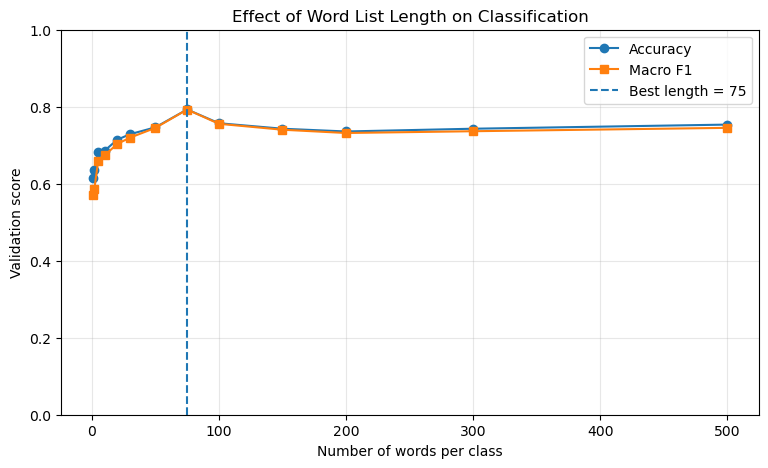

In [50]:
plt.figure(figsize=(9, 5))

plt.plot(
    experiment_results["Words per class"],
    experiment_results["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    experiment_results["Words per class"],
    experiment_results["Macro F1"],
    marker="s",
    label="Macro F1"
)

plt.axvline(
    best_length,
    linestyle="--",
    label=f"Best length = {best_length}"
)

plt.xlabel("Number of words per class")
plt.ylabel("Validation score")

plt.title("Effect of Word List Length on Classification")

plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

In [51]:
best_positive_words = positive_ranking[:best_length]
best_negative_words = negative_ranking[:best_length]

tuned_predictions = [
    predict_wordlist(
        review,
        best_positive_words,
        best_negative_words
    )
    for review, label in testing_data
]

tuned_metrics = evaluate(
    test_labels,
    tuned_predictions
)

In [52]:
final_comparison = pd.DataFrame({
    "Word List (10 words)": wordlist_metrics,
    f"Word List ({best_length} words)": tuned_metrics,
    "Naive Bayes": nb_metrics
}).T

display(final_comparison.round(3))

,Accuracy,Precision (pos),Recall (pos),F1 (pos),Precision (neg),Recall (neg),F1 (neg),Macro F1
Word List (10 words),0.660,0.603,0.933,0.733,0.853,0.387,0.532,0.633
Word List (75 words),0.763,0.748,0.793,0.770,0.780,0.733,0.756,0.763
Naive Bayes,0.785,0.798,0.763,0.780,0.773,0.807,0.790,0.785


### 5(a) — Results and Conclusions

The best **validation** result occurred with **75 words per class**, giving **0.793 macro F1** and **0.793 accuracy**. Validation macro F1 improved from **0.674** at ten words to **0.745** at 50 words, before peaking at 75. Increasing the lists further did not consistently improve performance: macro F1 fell to **0.756** at 100 words and was **0.745** at 500 words.

This suggests that adding informative words initially helps the classifier cover more reviews, while adding less distinctive words can introduce competing matches. The relationship was not monotonic, and 75 was the best length only among the sizes tested on this particular validation split.

After rebuilding the 75-word lists using all 1,400 training reviews, the model achieved **0.763 test accuracy** and **0.763 test macro F1**, compared with **0.660 accuracy** and **0.633 macro F1** for the original ten-word lists. The lower test score than the best validation score may reflect sampling variation. Results could be made more reliable by repeating the experiment with several training-validation splits. The method still ignores word order and negation.

### 5(b) — Recommendation

I would recommend **Naive Bayes** as the stronger baseline for future sentiment-classification work on similar reviews. Its test macro F1 was **0.785**, versus **0.763** for the tuned 75-word-list classifier, and its test accuracy was also higher (**0.785 versus 0.763**). The difference is modest (**2.2 percentage points** in both metrics), so these results should not be treated as proof that Naive Bayes will always perform better on new datasets.

The word-list classifier remains useful when transparency and simplicity are the main priorities, because individual predictions are easy to explain. However, Naive Bayes can learn from a wider vocabulary without requiring us to choose a small set of sentiment-associated words. Both methods miss relationships involving word order and negation; future work could examine n-grams and repeated train-test evaluations.

**Written answer word count: 1043 words** (excluding code, question prompts, graphs, tables and references).